In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('loan_data_new.csv')

print("Dataset size:", df.shape)
print(df.head())

Dataset size: (45000, 14)
   Age  Gender    Education  Person Income  Employee Experience  \
0   22  female       Master          71948                    0   
1   21  female  High School          12282                    0   
2   25  female  High School          12438                    3   
3   23  female     Bachelor          79753                    0   
4   24    male       Master          66135                    1   

  Home Onwership  Loan Amount Loan Intent  Loan interest Rate  \
0           RENT        35000    PERSONAL               16.02   
1            OWN         1000   EDUCATION               11.14   
2       MORTGAGE         5500     MEDICAL               12.87   
3           RENT        35000     MEDICAL               15.23   
4           RENT        35000     MEDICAL               14.27   

   Loan percentage  Credit History  Credit Score Previous Loan  Loan Status  
0             0.49               3           561            No            1  
1             0.08      

In [ ]:
features = [
    "Age",
    "Person Income",
    "Employee Experience",
    "Loan Amount",
    "Loan interest Rate",
    "Loan percentage",
    "Credit Score",
]

df_clean = df.dropna(subset=features + ["Home Onwership"]).copy()

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean[features])

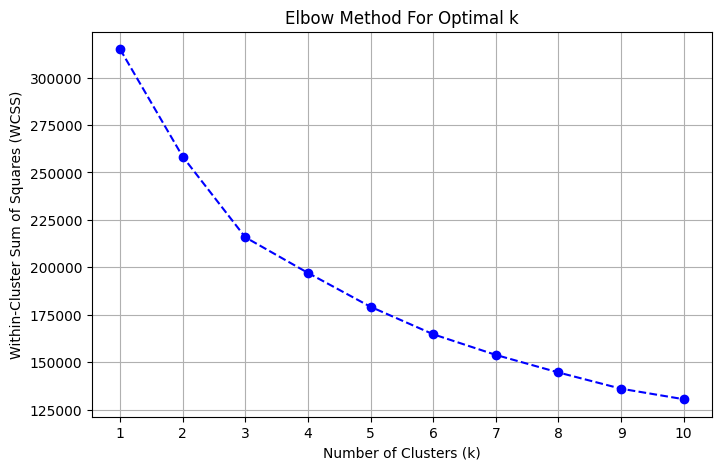


Inertia Values
----------------
k = 2: 315000.00
k = 3: 258350.99
k = 4: 215823.06
k = 5: 197054.60
k = 6: 179175.54
k = 7: 164704.24
k = 8: 153812.30
k = 9: 144547.86
k = 10: 135990.63
k = 11: 130448.30


In [ ]:
#elbow method to find optimal k
inertias = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range, inertias, marker="o", linestyle="--", color="b")
plt.title("Elbow Method For Optimal k")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.xticks(k_range)
plt.grid(True)
plt.show()

print("\nInertia Values")
print("----------------")

for i, value in enumerate(inertias):
    print(f"k = {i+2}: {value:.2f}")

In [ ]:
#running cluster model
k = 4

cluster_model = KMeans(n_clusters=k, random_state=42, n_init=10)
df["cluster"] = cluster_model.fit_predict(X_scaled)
print(df["cluster"].value_counts().sort_index())

cluster
0    10551
1    18072
2    10071
3     6306
Name: count, dtype: int64


In [ ]:
cluster_summary = df.groupby("cluster")[features].mean()

print(cluster_summary)

               Age  Person Income  Employee Experience   Loan Amount  \
cluster                                                                
0        26.457208   82206.977159             4.056393  17241.955739   
1        25.881253   75266.364819             3.557824   6394.727922   
2        25.460828   73105.287558             3.065237   7393.308410   
3        39.025690  103161.192991            16.729940   9403.533619   

         Loan interest Rate  Loan percentage  Credit Score  
cluster                                                     
0                 12.240210         0.243407    637.792816  
1                 10.427411         0.097827    658.123340  
2                 10.749193         0.116979    568.490219  
3                 11.013560         0.122645    653.214716  


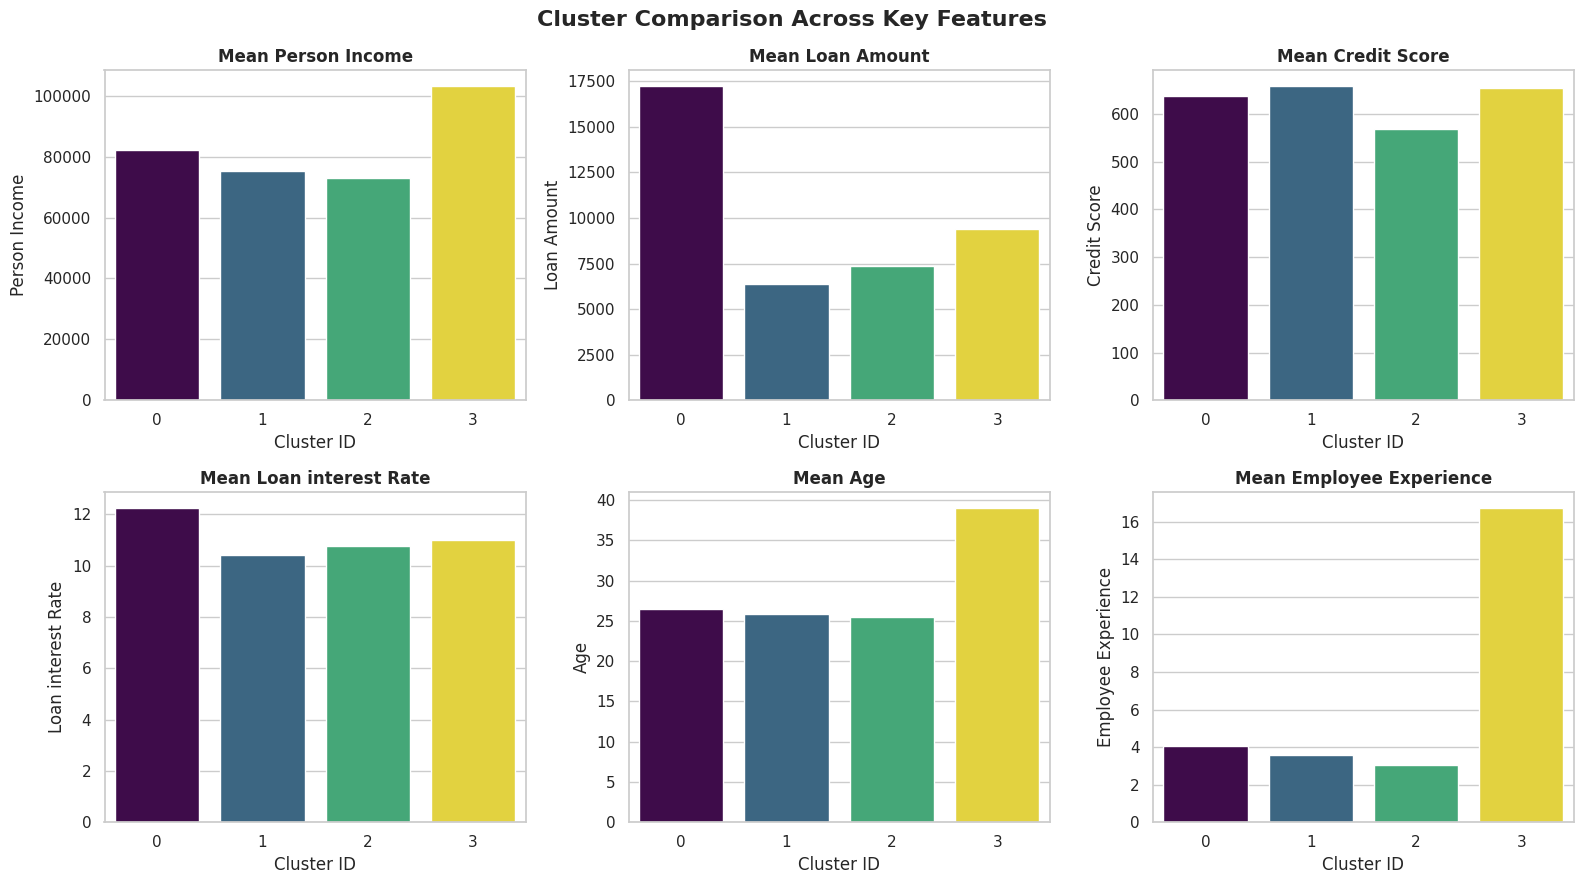

In [ ]:
#plotting mean values for each feature across clusters

features_to_plot = [
    "Person Income",
    "Loan Amount",
    "Credit Score",
    "Loan interest Rate",
    "Age",
    "Employee Experience",
]

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for idx, feature in enumerate(features_to_plot):
    sns.barplot(
        x=cluster_summary.index,
        y=cluster_summary[feature],
        ax=axes[idx],
        palette="viridis",
        hue=cluster_summary.index,
        legend=False,
    )
    axes[idx].set_title(f"Mean {feature}", fontsize=12, fontweight="bold")
    axes[idx].set_xlabel("Cluster ID")
    axes[idx].set_ylabel(feature)

plt.suptitle("Cluster Comparison Across Key Features", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()